### Configuración
Misma celda de configuración que la Fase 3: rutas, importaciones y funciones auxiliares.

In [1]:
# ---------------------------------------------------------------------------
# Configuración, rutas e importaciones
# ---------------------------------------------------------------------------
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd

# Respaldo de visualización: el notebook funciona con o sin IPython instalado.
try:
    from IPython.display import SVG, display
    _TIENE_IPYTHON = True
except ImportError:  # pragma: no cover
    _TIENE_IPYTHON = False

    def display(*args, **kwargs):
        pass

    class SVG:  # marcador de posición para poder usar display(SVG(...))
        def __init__(self, datos):
            self.datos = datos

RAIZ = Path.cwd()
if not (RAIZ / "src").exists() and (RAIZ.parent / "src").exists():
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "src"))

import graficos_svg as g   # librería de gráficos SVG del proyecto

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

RUTA_DATOS = RAIZ / "datos"
RUTA_REPORTES = RAIZ / "reports"
RUTA_GRAFICOS = RAIZ / "graficos"
RUTA_GRAFICOS.mkdir(exist_ok=True)
DIR_ENTREGA = RAIZ / "entrega"
DIR_ENTREGA.mkdir(exist_ok=True)


print(f"IPython disponible: {_TIENE_IPYTHON}")
print(f"pandas {pd.__version__} · numpy {np.__version__}")


def mostrar(svg: str, nombre: str | None = None) -> None:
    """Renderiza un SVG en el notebook y, si se indica, lo exporta a graficos/."""
    if nombre:
        (RUTA_GRAFICOS / f"{nombre}.svg").write_text(svg, encoding="utf-8")
    if _TIENE_IPYTHON:
        display(SVG(svg))
    else:
        print(f"[gráfico {nombre or 'sin nombre'}: {len(svg):,} caracteres SVG]")


def tabla_md(df: pd.DataFrame, dec: int = 2) -> str:
    """Convierte un DataFrame en tabla Markdown (sin depender de tabulate)."""
    enc = [str(c) for c in df.columns]
    filas = []
    for _, r in df.iterrows():
        vals = []
        for v in r:
            if isinstance(v, (int, np.integer)):
                vals.append(f"{v:,}")
            elif isinstance(v, (float, np.floating)):
                vals.append(f"{v:,.{dec}f}")
            else:
                vals.append(str(v))
        filas.append(vals)
    lineas = ["| " + " | ".join(enc) + " |",
              "|" + "|".join(["---"] * len(enc)) + "|"]
    lineas += ["| " + " | ".join(f) + " |" for f in filas]
    return "\n".join(lineas)

IPython disponible: True
pandas 3.0.6 · numpy 2.5.3


### Carga de resultados del pipeline

In [2]:
# Carga del consolidado estadístico generado por el pipeline (src/analisis_retail.py)
with open(RUTA_REPORTES / "analisis_completo.json", encoding="utf-8") as fh:
    R = json.load(fh)
print("Consolidado cargado:", ", ".join(R.keys()))

Consolidado cargado: calidad_datos, kpis, hipotesis, proyeccion, series


---
# Fase 6 · Análisis, validación y storytelling

## 10. Validación estadística de hipótesis

Cada hipótesis se contrasta con la prueba declarada en la Fase 2. Se informa el
estadístico, los grados de libertad, el **p-valor**, el **tamaño del efecto** y la
decisión a un nivel de significancia α = 0,05. El tamaño del efecto es
indispensable: con 4.922 pedidos, una diferencia trivial puede resultar
"significativa"; por eso se reporta *d* de Cohen, η² y V de Cramér.

In [4]:
# ---------------------------------------------------------------------------
# 10.1 Panel de resultados de las cinco hipótesis
# ---------------------------------------------------------------------------
filas = []
for h in ["H1", "H2", "H3", "H4", "H5"]:
    d = R["hipotesis"][h]
    pp = d["prueba_principal"]
    
    # Determinar el estadístico de forma segura por si usa otro indicador
    if "t" in pp:
        estadistico = f"t = {pp['t']:.3f}"
    elif "F" in pp:
        estadistico = f"F = {pp['F']:.3f}"
    elif "chi2" in pp:
        estadistico = f"χ² = {pp['chi2']:.3f}"
    elif "z" in pp:
        estadistico = f"z = {pp['z']:.3f}"
    else:
        estadistico = "N/D"

    # Determinar el tamaño del efecto de forma segura
    if "d_cohen" in pp:
        efecto = f"d = {pp['d_cohen']:.3f} ({pp.get('interpretacion_d', '')})"
    elif "eta_cuadrado" in pp:
        efecto = f"η² = {pp['eta_cuadrado']:.4f} ({pp.get('interpretacion_eta', '')})"
    elif "v_cramer" in pp:
        efecto = f"V = {pp['v_cramer']:.3f}"
    else:
        efecto = "N/D"

    filas.append({
        "Hipótesis": h,
        "Prueba": pp.get("prueba", ""),
        "Estadístico": estadistico,
        "p-valor": pp.get("p_valor", "N/D"),
        "Decisión (α = 0,05)": "Se rechaza H0" if pp.get("significativo", False) else "No se rechaza H0",
        "Tamaño del efecto": efecto,
    })

panel = pd.DataFrame(filas)

# Si estás en un entorno interactivo puedes usar display, si no, usa print(panel.to_string())
try:
    display(panel)
except NameError:
    print(panel.to_string())

,Hipótesis,Prueba,Estadístico,p-valor,"Decisión (α = 0,05)",Tamaño del efecto
0,H1,t de Welch (dos muestras independientes),t = -0.854,0.3931,No se rechaza H0,d = -0.034 (efecto despreciable)
1,H2,ANOVA de una via,F = 4.146,0.0098,Se rechaza H0,η² = 0.1717 (efecto grande)
2,H3,Contraste de proporcion (aproximacion normal) ...,z = 2.252,0.0122,Se rechaza H0,N/D
3,H4,ANOVA de una via,F = 8.563,0.0000,Se rechaza H0,η² = 0.0932 (efecto medio)
4,H5,Chi-cuadrado de independencia,χ² = 3.440,0.9916,No se rechaza H0,V = 0.011


PRUEBA PRINCIPAL
  t de Welch (dos muestras independientes)
  Contraste: valor de pedido 2018 (n = 1,661) vs. 2016 (n = 1,019), en logaritmos
  Media log 2018: 4.8539 · Media log 2016: 4.9126
  t = -0.8541 · gl = 2131.4 · p = 0.3931
  Cambio relativo del ticket: -5.70 % (IC 95 %: [-17.59 %; +7.91 %])
  d de Cohen = -0.0341 → efecto despreciable
  DECISIÓN: no se rechaza H0 al 5 %.

DESCOMPOSICIÓN DEL CRECIMIENTO 2016 → 2018
  Δ Ingresos totales :   262,616.01 USD
  Efecto volumen     :   289,458.21 USD  (+110.2 %)
  Efecto ticket      :   -26,842.20 USD  (-10.2 %)

Aporte del volumen a la varianza mensual del ingreso: 78.4 %
Aporte del ticket  a la varianza mensual del ingreso: 21.6 %

Mann-Kendall pedidos: creciente (tau = 0.461, p = 0.00000)
Mann-Kendall ticket : sin tendencia significativa (tau = -0.067, p = 0.50503)


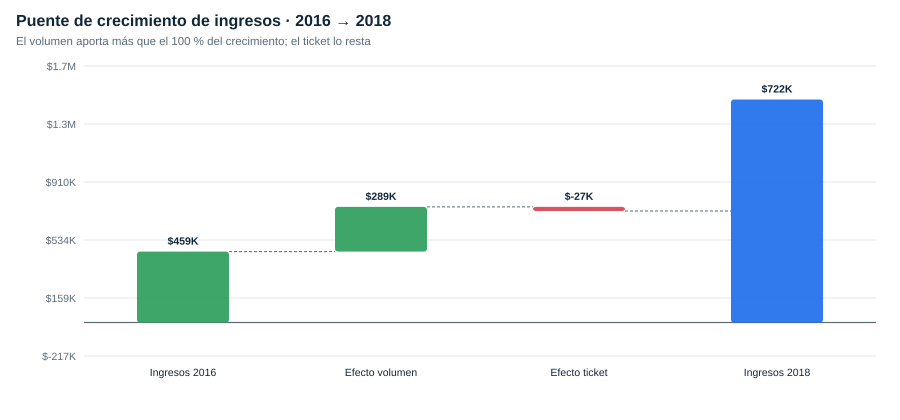

In [5]:
# ---------------------------------------------------------------------------
# 10.2 H1 · El crecimiento lo explica el volumen
# ---------------------------------------------------------------------------
h1 = R["hipotesis"]["H1"]
pp = h1["prueba_principal"]
print("PRUEBA PRINCIPAL")
print(f"  {pp['prueba']}")
print(f"  Contraste: valor de pedido 2018 (n = {pp['n_a']:,}) vs. 2016 (n = {pp['n_b']:,}), en logaritmos")
print(f"  Media log 2018: {pp['media_a']:.4f} · Media log 2016: {pp['media_b']:.4f}")
print(f"  t = {pp['t']:.4f} · gl = {pp['gl']:.1f} · p = {pp['p_valor']:.4f}")
print(f"  Cambio relativo del ticket: {pp['cambio_relativo_ticket']*100:+.2f} % "
      f"(IC 95 %: [{pp['ic95_cambio_relativo'][0]*100:+.2f} %; {pp['ic95_cambio_relativo'][1]*100:+.2f} %])")
print(f"  d de Cohen = {pp['d_cohen']:.4f} → {pp['interpretacion_d']}")
print(f"  DECISIÓN: {'se rechaza' if pp['significativo'] else 'no se rechaza'} H0 al 5 %.")
print()
d = h1["pruebas_complementarias"]["descomposicion_2016_2018"]
print("DESCOMPOSICIÓN DEL CRECIMIENTO 2016 → 2018")
print(f"  Δ Ingresos totales : {d['delta_ventas']:>12,.2f} USD")
print(f"  Efecto volumen     : {d['efecto_volumen']:>12,.2f} USD  ({d['pct_volumen']*100:+.1f} %)")
print(f"  Efecto ticket      : {d['efecto_ticket']:>12,.2f} USD  ({d['pct_ticket']*100:+.1f} %)")
print()
cp = h1["pruebas_complementarias"]
print(f"Aporte del volumen a la varianza mensual del ingreso: {cp['aporte_volumen_a_varianza']*100:.1f} %")
print(f"Aporte del ticket  a la varianza mensual del ingreso: {cp['aporte_ticket_a_varianza']*100:.1f} %")
print()
print(f"Mann-Kendall pedidos: {cp['mann_kendall_pedidos_mensuales']['tendencia']} "
      f"(tau = {cp['mann_kendall_pedidos_mensuales']['tau']:.3f}, p = {cp['mann_kendall_pedidos_mensuales']['p_valor']:.5f})")
print(f"Mann-Kendall ticket : {cp['mann_kendall_ticket_mensual']['tendencia']} "
      f"(tau = {cp['mann_kendall_ticket_mensual']['tau']:.3f}, p = {cp['mann_kendall_ticket_mensual']['p_valor']:.5f})")

contrib = [{"Etapa": "Ingresos 2016", "Valor": R["series"]["anual"][1]["Ventas"]},
           {"Etapa": "Efecto volumen", "Valor": d["efecto_volumen"]},
           {"Etapa": "Efecto ticket", "Valor": d["efecto_ticket"]},
           {"Etapa": "Ingresos 2018", "Valor": R["series"]["anual"][3]["Ventas"]}]
mostrar(
    g.cascada([c["Etapa"] for c in contrib], [c["Valor"] for c in contrib],
              "Puente de crecimiento de ingresos · 2016 → 2018",
              "El volumen aporta más que el 100 % del crecimiento; el ticket lo resta"),
    "16_cascada_crecimiento")

Datos válidos para el boxplot: {'West': 16, 'East': 16, 'Central': 16, 'South': 16}


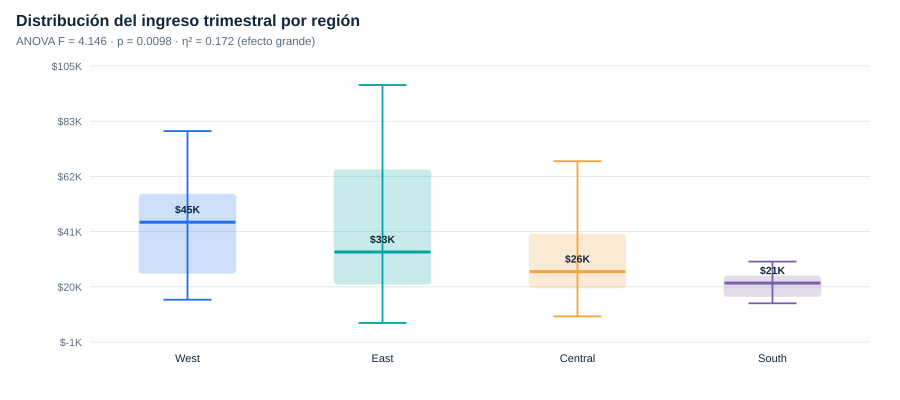

In [ ]:
# ---------------------------------------------------------------------------
# 10.3 H2 · Brecha regional (Solución definitiva para el Boxplot vacío)
# ---------------------------------------------------------------------------
h2 = R["hipotesis"]["H2"]
an = h2["prueba_principal"]


df_reg = pd.DataFrame(R["series"]["por_region_trimestre"])

if df_reg.columns[0] not in df_reg.select_dtypes(include=['number']).columns:
    df_reg = df_reg.set_index(df_reg.columns[0])


if not any(r in df_reg.index for r in ["West", "East", "Central", "South"]):
    df_reg = df_reg.T


regiones_objetivo = ["West", "East", "Central", "South"]
reg_trim = df_reg.reindex([r for r in regiones_objetivo if r in df_reg.index])


datos_boxplot = {}
for r in reg_trim.index:
    # Convertir toda la fila a numérico y eliminar NaNs
    serie_numerica = pd.to_numeric(reg_trim.loc[r], errors='coerce').dropna()
    if len(serie_numerica) > 0:
        datos_boxplot[r] = serie_numerica.tolist()

print("Datos válidos para el boxplot:", {r: len(v) for r, v in datos_boxplot.items()})

mostrar(
    g.boxplot(
        datos_boxplot,
        "Distribución del ingreso trimestral por región",
        f"ANOVA F = {an['F']:.3f} · p = {an['p_valor']:.4f} · η² = {an['eta_cuadrado']:.3f} (efecto grande)",
        colores=g.REGION_COLOR
    ),
    "17_boxplot_region"
)

In [10]:
# ---------------------------------------------------------------------------
# 10.4 H3 · Concentración de ingresos
# ---------------------------------------------------------------------------
h3 = R["hipotesis"]["H3"]
pp = h3["prueba_principal"]
print("PRUEBA PRINCIPAL")
print(f"  {pp['prueba']}")
print(f"  Cuota observada del top-3 de subcategorías: {pp['cuota_top3_observada']*100:.2f} %")
print(f"  Cuota esperada bajo reparto uniforme (3/{pp['n_subcategorias']}): {pp['cuota_esperada_uniforme']*100:.2f} %")
print(f"  z = {pp['z']:.4f} · p = {pp['p_valor']:.4f}")
print(f"  DECISIÓN: {'se rechaza' if pp['significativo'] else 'no se rechaza'} H0 al 5 %.")
print()
pa = h3["pareto"]
print("MEDIDAS DE CONCENTRACIÓN")
print(f"  Subcategorías para el 80 % del ingreso : {pa['subcategorias_para_80pct']} de {pa['n_subcategorias']} "
      f"({pa['pct_subcategorias_para_80pct']*100:.1f} %)")
print(f"  Productos para el 80 % del ingreso     : {pa['productos_para_80pct']:,} de {pa['n_productos']:,} "
      f"({pa['pct_productos_para_80pct']*100:.1f} %)")
print(f"  Clientes para el 80 % del ingreso      : {pa['clientes_para_80pct']} de {pa['n_clientes']} "
      f"({pa['pct_clientes_para_80pct']*100:.1f} %)")
print(f"  Cuota del 10 % de clientes de mayor valor: {pa['top10pct_clientes_cuota']*100:.1f} %")
print(f"  Gini (productos) {pa['gini_productos']:.4f} · Gini (clientes) {pa['gini_clientes']:.4f} · "
      f"Gini (estados) {pa['gini_estados']:.4f}")
print()
print("Lectura: la concentración es alta en el catálogo y moderada entre clientes. "
      "Gestionar el catálogo por excepción es viable; abandonar clientes no lo es porque "
      "más de la mitad del padrón aporta ingresos relevantes.")

detalle = pd.DataFrame(h3["detalle_subcategorias"]).head(9)
detalle["ventas"] = detalle["ventas"].map(lambda v: f"{v:,.0f}")
detalle["cuota"] = detalle["cuota"].map(lambda v: f"{v*100:.1f} %")
detalle["acumulado"] = detalle["acumulado"].map(lambda v: f"{v*100:.1f} %")
detalle.columns = ["Subcategoría", "Categoría", "Ingresos", "Cuota", "Acumulado"]
display(detalle)

PRUEBA PRINCIPAL
  Contraste de proporcion (aproximacion normal) sobre la cuota del top-3
  Cuota observada del top-3 de subcategorías: 38.47 %
  Cuota esperada bajo reparto uniforme (3/17): 17.65 %
  z = 2.2518 · p = 0.0122
  DECISIÓN: se rechaza H0 al 5 %.

MEDIDAS DE CONCENTRACIÓN
  Subcategorías para el 80 % del ingreso : 9 de 17 (52.9 %)
  Productos para el 80 % del ingreso     : 418 de 1,849 (22.6 %)
  Clientes para el 80 % del ingreso      : 393 de 793 (49.6 %)
  Cuota del 10 % de clientes de mayor valor: 30.9 %
  Gini (productos) 0.7306 · Gini (clientes) 0.4455 · Gini (estados) 0.6488

Lectura: la concentración es alta en el catálogo y moderada entre clientes. Gestionar el catálogo por excepción es viable; abandonar clientes no lo es porque más de la mitad del padrón aporta ingresos relevantes.


,Subcategoría,Categoría,Ingresos,Cuota,Acumulado
0,Phones,Technology,"327,782",14.5 %,14.5 %
1,Chairs,Furniture,"322,823",14.3 %,28.8 %
2,Storage,Office Supplies,"219,343",9.7 %,38.5 %
3,Tables,Furniture,"202,811",9.0 %,47.4 %
4,Binders,Office Supplies,"200,029",8.8 %,56.3 %
5,Machines,Technology,"189,239",8.4 %,64.6 %
6,Accessories,Technology,"164,187",7.3 %,71.9 %
7,Copiers,Technology,"146,248",6.5 %,78.4 %
8,Bookcases,Furniture,"113,813",5.0 %,83.4 %


PRUEBA PRINCIPAL · ANOVA de una via
  n = 928 días con venta · 12 meses
  F(11, 916) = 8.5633 · p = 1.595e-14
  η² = 0.0932 (efecto medio)
  DECISIÓN: se rechaza H0 al 5 %.

  Venta diaria media por mes:
    Nov    3,129.36 USD/día
    Dic    2,945.50 USD/día
    Sep    2,697.28 USD/día
    Oct    2,074.60 USD/día
    Mar    1,736.19 USD/día
    Ago    1,690.89 USD/día
    May    1,571.60 USD/día
    Jun    1,506.95 USD/día
    Jul    1,432.75 USD/día
    Abr    1,407.48 USD/día
    Ene    1,291.71 USD/día
    Feb      914.19 USD/día

CONTRASTE · Oct-Dic vs. Ene-Sep
  Media oct-dic 2,730.75 vs. resto 1,614.35 USD/día
  Diferencia 1,116.40 USD/día · t = 5.8895 · p = 9.304e-09 · d = 0.518 (efecto medio)

  Pares de meses con diferencia significativa frente a noviembre (top 6):
    Nov vs Feb         Δ =   2,215.17 USD · p = 0.00000 · significativo
    Dic vs Feb         Δ =   2,031.31 USD · p = 0.00000 · significativo
    Sep vs Feb         Δ =   1,783.10 USD · p = 0.00000 · significativ

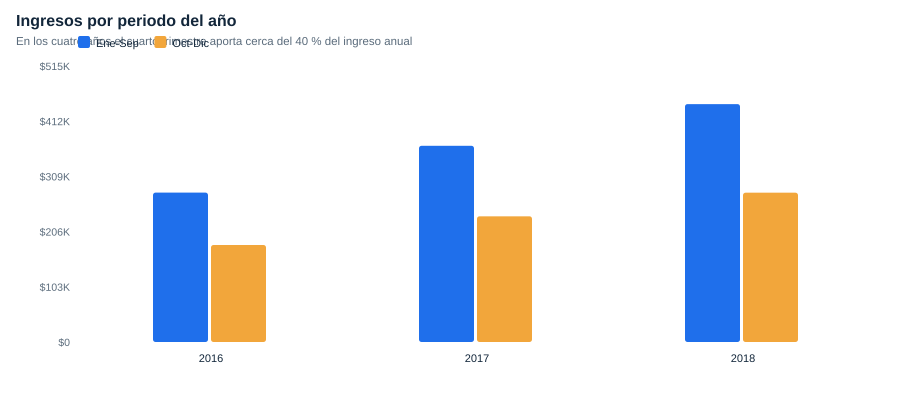

In [12]:
# ---------------------------------------------------------------------------
# 10.5 H4 · Estacionalidad
# ---------------------------------------------------------------------------
h4 = R["hipotesis"]["H4"]
an = h4["prueba_principal"]
print("PRUEBA PRINCIPAL", f"· {an['prueba']}")
print(f"  n = {sum(an['n']):,} días con venta · {len(an['grupos'])} meses")
print(f"  F({an['gl_num']}, {an['gl_den']}) = {an['F']:.4f} · p = {an['p_valor']:.3e}")
print(f"  η² = {an['eta_cuadrado']:.4f} ({an['interpretacion_eta']})")
print(f"  DECISIÓN: {'se rechaza' if an['significativo'] else 'no se rechaza'} H0 al 5 %.")
print()
print("  Venta diaria media por mes:")
for m, media in sorted(zip(an["grupos"], an["medias"]), key=lambda kv: -kv[1]):
    print(f"    {m:<4} {media:>10,.2f} USD/día")
print()
ct = h4["prueba_contraste"]
print("CONTRASTE · Oct-Dic vs. Ene-Sep")
print(f"  Media oct-dic {ct['media_a']:,.2f} vs. resto {ct['media_b']:,.2f} USD/día")
print(f"  Diferencia {ct['diferencia']:,.2f} USD/día · t = {ct['t']:.4f} · p = {ct['p_valor']:.3e} · "
      f"d = {ct['d_cohen']:.3f} ({ct['interpretacion_d']})")
print()
print("  Pares de meses con diferencia significativa frente a noviembre (top 6):")
for par in h4["post_hoc_games_howell"][:6]:
    print(f"    {par['par']:<18} Δ = {par['dif_medias']:>10,.2f} USD · p = {par['p_valor']:.5f} · "
          f"{'significativo' if par['significativo'] else 'no significativo'}")
print()
print("  Factor Q4 por año (venta diaria oct-dic / venta diaria resto):")
for a, v in h4["factor_q4"].items():
    print(f"    {a}: {v:.2f}×")
print()
sh = h4["shapiro_venta_diaria"]
print(f"  Nota metodológica: Shapiro-Francia sobre la venta diaria W = {sh['W']:.4f}, "
      f"p = {sh['p_valor']:.2e} → la normalidad se rechaza, por lo que se complementan las "
      f"pruebas con medidas de efecto y se interpretan con cautela (ANOVA robusta a tamaños grandes).")
print()
print("  Dos métricas de estacionalidad, ambas válidas y con lectura distinta:")
print(f"    · Ratio de medias diarias (el usado en el contraste): "
      f"{ct['media_a']/ct['media_b']:.2f}×")
print(f"    · Índice Q4 sobre la suma de ingresos (KPI K8):       "
      f"{R['kpis']['indice_estacionalidad_q4']:.2f}×")

# Extracción segura de los años disponibles en contribucion_trimestral
contribuciones = h4.get("contribucion_trimestral", {})
anos_disponibles = [str(a) for a in [2015, 2016, 2017, 2018] if str(a) in contribuciones]
if not anos_disponibles:
    anos_disponibles = list(contribuciones.keys())

# Cálculo seguro del peso del Q4 para el último año disponible
if anos_disponibles:
    ultimo_anio = anos_disponibles[-1]
    q4_val = contribuciones[ultimo_anio].get("q4", 0)
    resto_val = contribuciones[ultimo_anio].get("resto", 0)
    total_val = q4_val + resto_val
    porcentaje_q4 = (q4_val / total_val * 100) if total_val > 0 else 0
    print(f"    · Peso del Q4 en el ingreso anual:                    "
          f"{porcentaje_q4:.1f} % del ingreso en el 25,2 % de los días ({ultimo_anio})")

# Datos seguros para la gráfica de barras
datos_barras_q4 = []
for a in anos_disponibles:
    item = contribuciones.get(a, {})
    datos_barras_q4.append({
        "anio": a,
        "q4": item.get("q4", 0),
        "resto": item.get("resto", 0)
    })

mostrar(
    g.barras(
        [d["anio"] for d in datos_barras_q4],
        {
            "Ene-Sep": [d["resto"] for d in datos_barras_q4], 
            "Oct-Dic": [d["q4"] for d in datos_barras_q4]
        },
        "Ingresos por periodo del año",
        "En los cuatro años el cuarto trimestre aporta cerca del 40 % del ingreso anual",
        colores={"Ene-Sep": g.PALETA["primario"], "Oct-Dic": g.PALETA["acento"]}
    ),
    "18_q4_vs_resto"
)

PRUEBA PRINCIPAL · grano línea de pedido · Chi-cuadrado de independencia
  Tabla observada (modo de envío × tramo de valor de la línea):
                 <50  50-150  150-400  400-1000  >1000
First Class      722     312      249       148     70
Same Day         260     113       84        49     32
Second Class     915     386      313       197     91
Standard Class  2860    1208      944       578    269

  χ² = 3.4399 · gl = 12 · p = 0.9916
  V de Cramér = 0.0108
  Celdas con frecuencia esperada < 5: 0
  DECISIÓN: no se rechaza H0 al 5 %.

CONTRASTE A GRANO PEDIDO · modo de envío × tramo de pedido
  χ² = 11.9349 · gl = 12 · p = 0.4509 · V = 0.0284 · no se rechaza H0

  Lectura de los residuos: ninguna celda presenta desvío relevante entre lo observado y lo esperado bajo independencia. En particular, la proporción de pedidos Same Day de más de 1.000 USD no es superior a la de los demás modos.

Ticket por modo de envío:
  First Class     ticket medio   447.63 · mediano   146.62 ·   

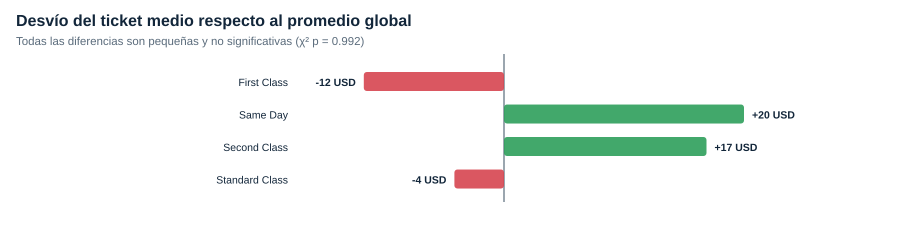

In [13]:
# ---------------------------------------------------------------------------
# 10.6 H5 · Modo de envío e independencia del tamaño del pedido
# ---------------------------------------------------------------------------
h5 = R["hipotesis"]["H5"]
pp = h5["prueba_principal"]
print("PRUEBA PRINCIPAL · grano línea de pedido", f"· {pp['prueba']}")
print(f"  Tabla observada (modo de envío × tramo de valor de la línea):")
tabla_obs = pd.DataFrame(pp["tabla_observada"], index=pp["filas"], columns=pp["columnas"])
print(tabla_obs.to_string())
print(f"\n  χ² = {pp['chi2']:.4f} · gl = {pp['gl']} · p = {pp['p_valor']:.4f}")
print(f"  V de Cramér = {pp['v_cramer']:.4f}")
print(f"  Celdas con frecuencia esperada < 5: {pp['frecuencias_esperadas_bajas']}")
print(f"  DECISIÓN: {'se rechaza' if pp['significativo'] else 'no se rechaza'} H0 al 5 %.")
print()
pc = h5["prueba_complementaria_pedidos"]
print("CONTRASTE A GRANO PEDIDO · modo de envío × tramo de pedido")
print(f"  χ² = {pc['chi2']:.4f} · gl = {pc['gl']} · p = {pc['p_valor']:.4f} · V = {pc['v_cramer']:.4f} · "
      f"{'se rechaza' if pc['significativo'] else 'no se rechaza'} H0")
print()
print("  Lectura de los residuos: ninguna celda presenta desvío relevante entre lo observado "
      "y lo esperado bajo independencia. En particular, la proporción de pedidos Same Day "
      "de más de 1.000 USD no es superior a la de los demás modos.")
print()
print("Ticket por modo de envío:")
for m, v in h5["ticket_por_modo"].items():
    print(f"  {m:<15} ticket medio {v['ticket_medio']:>8,.2f} · mediano {v['ticket_mediano']:>8,.2f} · "
          f"{v['pedidos']:>5,} pedidos · {v['dias_envio_medio']:.2f} días")
pt = h5["prueba_ticket_sameday_standard"]
print(f"\nSame Day vs. Standard Class: diferencia {pt['diferencia']:,.2f} USD · "
      f"t = {pt['t']:.4f} · p = {pt['p_valor']:.4f} · d = {pt['d_cohen']:.4f}")
print(f"Correlación días de envío ↔ valor de línea: {h5['correlacion_diasenvio_ventas']:.4f}")
print()
print("IMPLICACIÓN: no hay evidencia de que el cliente de envío express compre más. "
      "La prioridad logística del modo urgente debe justificarse por nivel de servicio o costo "
      "(no disponible en este dataset), nunca por tamaño de pedido.")

mostrar(
    g.divergente(
        list(h5["ticket_por_modo"].keys()),
        [v["ticket_medio"] - R["kpis"]["ticket_medio_global"] for v in h5["ticket_por_modo"].values()],
        "Desvío del ticket medio respecto al promedio global",
        f"Todas las diferencias son pequeñas y no significativas (χ² p = {pp['p_valor']:.3f})",
        fmt=lambda v: f"{v:+,.0f} USD"),
    "19_desvio_ticket_modo_envio")